# 04 — Chicago Crime Statistical Insights and Pattern Detection

# Use Case 3 — Statistical Insights and Pattern Detection

This notebook will be completed after the exploratory analysis.

Planned analysis:
1. Hourly crime distribution using the crime timestamp.
2. Mean crime count by community area.
3. Box plot and IQR method to identify high-crime-count community-area outliers.
4. Correlation matrix for available numeric variables.
5. Interpretation of the statistical results and limitations.

We will distinguish association from causation and avoid treating this small uploaded extract as a representative sample of all Chicago crime.

## Work log

We will add executable code cells and validate their outputs during the corresponding project phase.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from pathlib import Path

# Connect to SQLite database
DB_PATH = Path("../data/database/chicago_crime.db")

connection = sqlite3.connect(DB_PATH)

# Load crime records
crime_df = pd.read_sql_query(
    "SELECT * FROM crimes",
    connection
)

# Convert date column to datetime
crime_df["date"] = pd.to_datetime(
    crime_df["date"],
    errors="coerce"
)

print("Statistical analysis dataset loaded.")
print("Dataset shape:", crime_df.shape)

display(crime_df.head())

Statistical analysis dataset loaded.
Dataset shape: (498, 23)


,id,case_number,date,block,iucr_code,location_desc,arrest,domestic,beat_num,district_code,...,x_coordinate,y_coordinate,year,date_of_update,latitude,longitude,location,Month,DayOfWeek,primary_type
0,10508693,HZ250496,2016-05-03,013XX S SAWYER AVE,486,APARTMENT,1,1,1022,10,...,1154907.0,1893681.0,2016,2016-05-10,41.864073,-87.706819,"(41.864073157, -87.706818608)",5,TUESDAY,BATTERY
1,10508695,HZ250409,2016-05-03,061XX S DREXEL AVE,486,RESIDENCE,0,1,313,3,...,1183066.0,1864330.0,2016,2016-05-10,41.782922,-87.604363,"(41.782921527, -87.60436317)",5,TUESDAY,BATTERY
2,10508697,HZ250503,2016-05-03,053XX W CHICAGO AVE,470,STREET,0,0,1524,15,...,1140789.0,1904819.0,2016,2016-05-10,41.894908,-87.758372,"(41.894908283, -87.758371958)",5,TUESDAY,PUBLIC PEACE VIOLATION
3,10508698,HZ250424,2016-05-03,049XX W FULTON ST,460,SIDEWALK,0,0,1532,15,...,1143223.0,1901475.0,2016,2016-05-10,41.885687,-87.749516,"(41.885686845, -87.749515983)",5,TUESDAY,BATTERY
4,10508699,HZ250455,2016-05-03,003XX N LOTUS AVE,820,RESIDENCE,0,1,1523,15,...,1139890.0,1901675.0,2016,2016-05-10,41.886297,-87.761751,"(41.886297242, -87.761750709)",5,TUESDAY,THEFT


In [2]:
# Inspect all available columns
print("Available columns:")
print(crime_df.columns.tolist())

# Check the original date values
print("\nSample date values:")
display(crime_df["date"].head(10))

# Check whether any column contains time information
time_columns = [
    column for column in crime_df.columns
    if "time" in column.lower()
    or "hour" in column.lower()
]

print("\nPossible time-related columns:", time_columns)

Available columns:
['id', 'case_number', 'date', 'block', 'iucr_code', 'location_desc', 'arrest', 'domestic', 'beat_num', 'district_code', 'ward_no', 'community_code', 'fbi_code', 'x_coordinate', 'y_coordinate', 'year', 'date_of_update', 'latitude', 'longitude', 'location', 'Month', 'DayOfWeek', 'primary_type']

Sample date values:


0   2016-05-03
1   2016-05-03
2   2016-05-03
3   2016-05-03
4   2016-05-03
5   2016-05-03
6   2016-05-03
7   2016-05-03
8   2016-05-03
9   2016-05-03
Name: date, dtype: datetime64[us]


Possible time-related columns: []


In [4]:
# Calculate daily crime counts by community area

daily_community_crimes = (
    crime_df.groupby(
        ["community_code", "date"]
    )
    .size()
    .reset_index(name="daily_crimes")
)

# Calculate community-area statistics

community_stats = (
    daily_community_crimes.groupby("community_code")
    .agg(
        total_crimes=("daily_crimes", "sum"),
        average_daily_crimes=("daily_crimes", "mean"),
        maximum_daily_crimes=("daily_crimes", "max")
    )
    .reset_index()
)

# Calculate arrests by community area

community_arrests = (
    crime_df.groupby("community_code")["arrest"]
    .sum()
    .reset_index(name="total_arrests")
)

# Merge statistics

community_stats = community_stats.merge(
    community_arrests,
    on="community_code",
    how="left"
)

community_stats = community_stats.sort_values(
    by="total_crimes",
    ascending=False
)

print("Community Area Statistical Summary:")

display(community_stats.head(10))

Community Area Statistical Summary:


,community_code,total_crimes,average_daily_crimes,maximum_daily_crimes,total_arrests
21,25,34,6.800000,21,13
6,8,20,3.333333,10,5
19,23,20,5.000000,14,6
26,30,16,3.200000,10,4
39,43,16,5.333333,10,5
62,68,16,5.333333,12,4
28,32,15,7.500000,9,3
4,6,14,3.500000,7,2
45,49,14,4.666667,10,5
65,71,14,2.800000,9,4


In [5]:
# Calculate crime counts by community area

community_counts = crime_df.groupby(
    "community_code"
).size()

# Calculate quartiles

Q1 = community_counts.quantile(0.25)
Q3 = community_counts.quantile(0.75)

IQR = Q3 - Q1

# Calculate outlier boundaries

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers

outliers = community_counts[
    (community_counts < lower_bound) |
    (community_counts > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nOutlier Community Areas:")
display(outliers)

Q1: 3.0
Q3: 9.0
IQR: 6.0
Lower Bound: -6.0
Upper Bound: 18.0

Outlier Community Areas:


community_code
8     20
23    20
25    34
dtype: int64

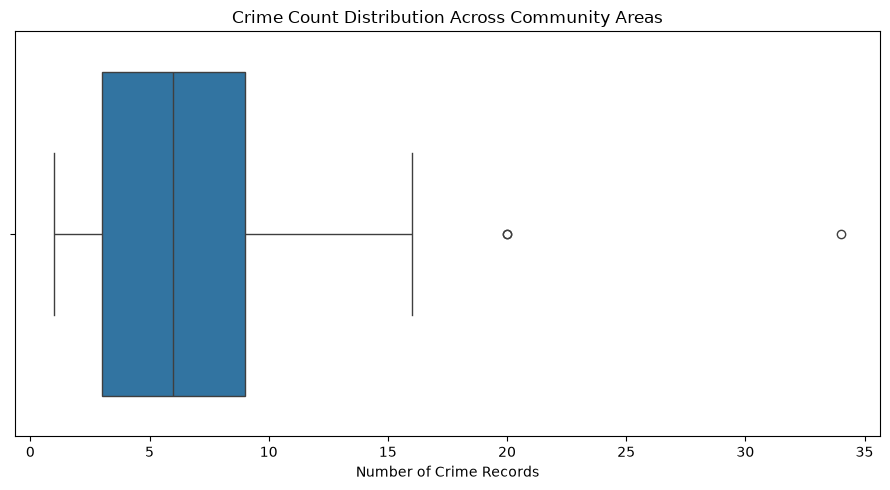

In [6]:
plt.figure(figsize=(9, 5))

sns.boxplot(x=community_counts)

plt.title("Crime Count Distribution Across Community Areas")
plt.xlabel("Number of Crime Records")

plt.tight_layout()
plt.show()

In [7]:
# Calculate quartiles
Q1 = community_counts.quantile(0.25)
Q3 = community_counts.quantile(0.75)

IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = community_counts[
    (community_counts < lower_bound) |
    (community_counts > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

print("\nOutlier community areas:")
display(outliers)

Q1: 3.0
Q3: 9.0
IQR: 6.0
Lower boundary: -6.0
Upper boundary: 18.0

Outlier community areas:


community_code
8     20
23    20
25    34
dtype: int64

In [8]:
# Select numerical columns for correlation analysis

numeric_columns = [
    "arrest",
    "domestic",
    "beat_num",
    "district_code",
    "ward_no",
    "community_code",
    "x_coordinate",
    "y_coordinate",
    "year",
    "Month",
    "latitude",
    "longitude"
]

# Create numerical dataset
numeric_df = crime_df[numeric_columns].copy()

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlation matrix
display(correlation_matrix.round(2))

,arrest,domestic,beat_num,district_code,ward_no,community_code,x_coordinate,y_coordinate,year,Month,latitude,longitude
arrest,1.00,0.01,0.02,0.02,0.03,-0.06,-0.03,-0.01,-0.13,-0.18,-0.01,-0.03
domestic,0.01,1.00,-0.01,-0.01,-0.00,0.01,-0.03,0.01,0.02,0.03,0.01,-0.03
beat_num,0.02,-0.01,1.00,1.00,0.72,-0.47,-0.57,0.64,-0.13,-0.10,0.64,-0.56
district_code,0.02,-0.01,1.00,1.00,0.72,-0.47,-0.57,0.64,-0.13,-0.10,0.64,-0.56
ward_no,0.03,-0.00,0.72,0.72,1.00,-0.55,-0.48,0.70,-0.06,-0.05,0.70,-0.48
community_code,-0.06,0.01,-0.47,-0.47,-0.55,1.00,0.30,-0.74,0.09,0.01,-0.74,0.29
x_coordinate,-0.03,-0.03,-0.57,-0.57,-0.48,0.30,1.00,-0.57,0.05,0.00,-0.57,1.00
y_coordinate,-0.01,0.01,0.64,0.64,0.70,-0.74,-0.57,1.00,-0.04,-0.11,1.00,-0.56
year,-0.13,0.02,-0.13,-0.13,-0.06,0.09,0.05,-0.04,1.00,0.15,-0.04,0.05
Month,-0.18,0.03,-0.10,-0.10,-0.05,0.01,0.00,-0.11,0.15,1.00,-0.11,0.00


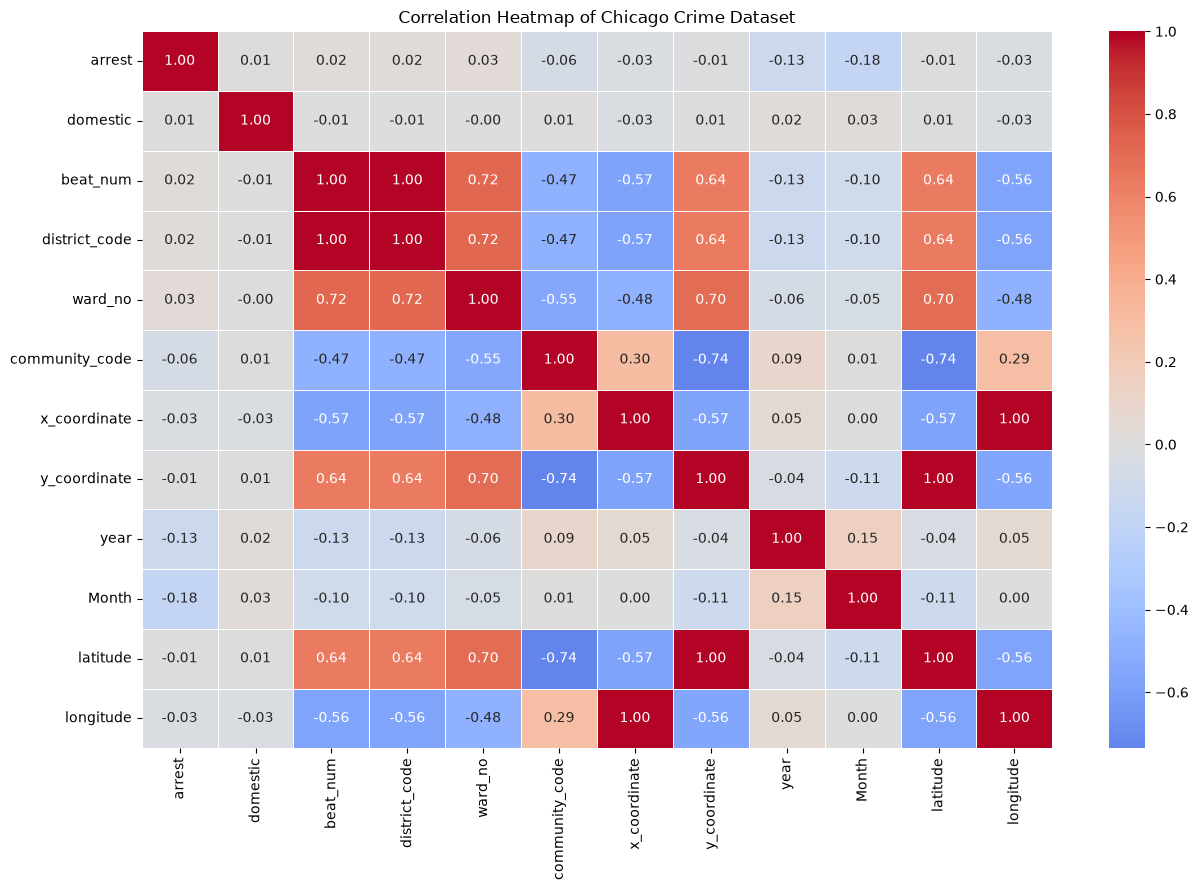

In [9]:
# Plot correlation heatmap

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Chicago Crime Dataset")

plt.tight_layout()
plt.show()